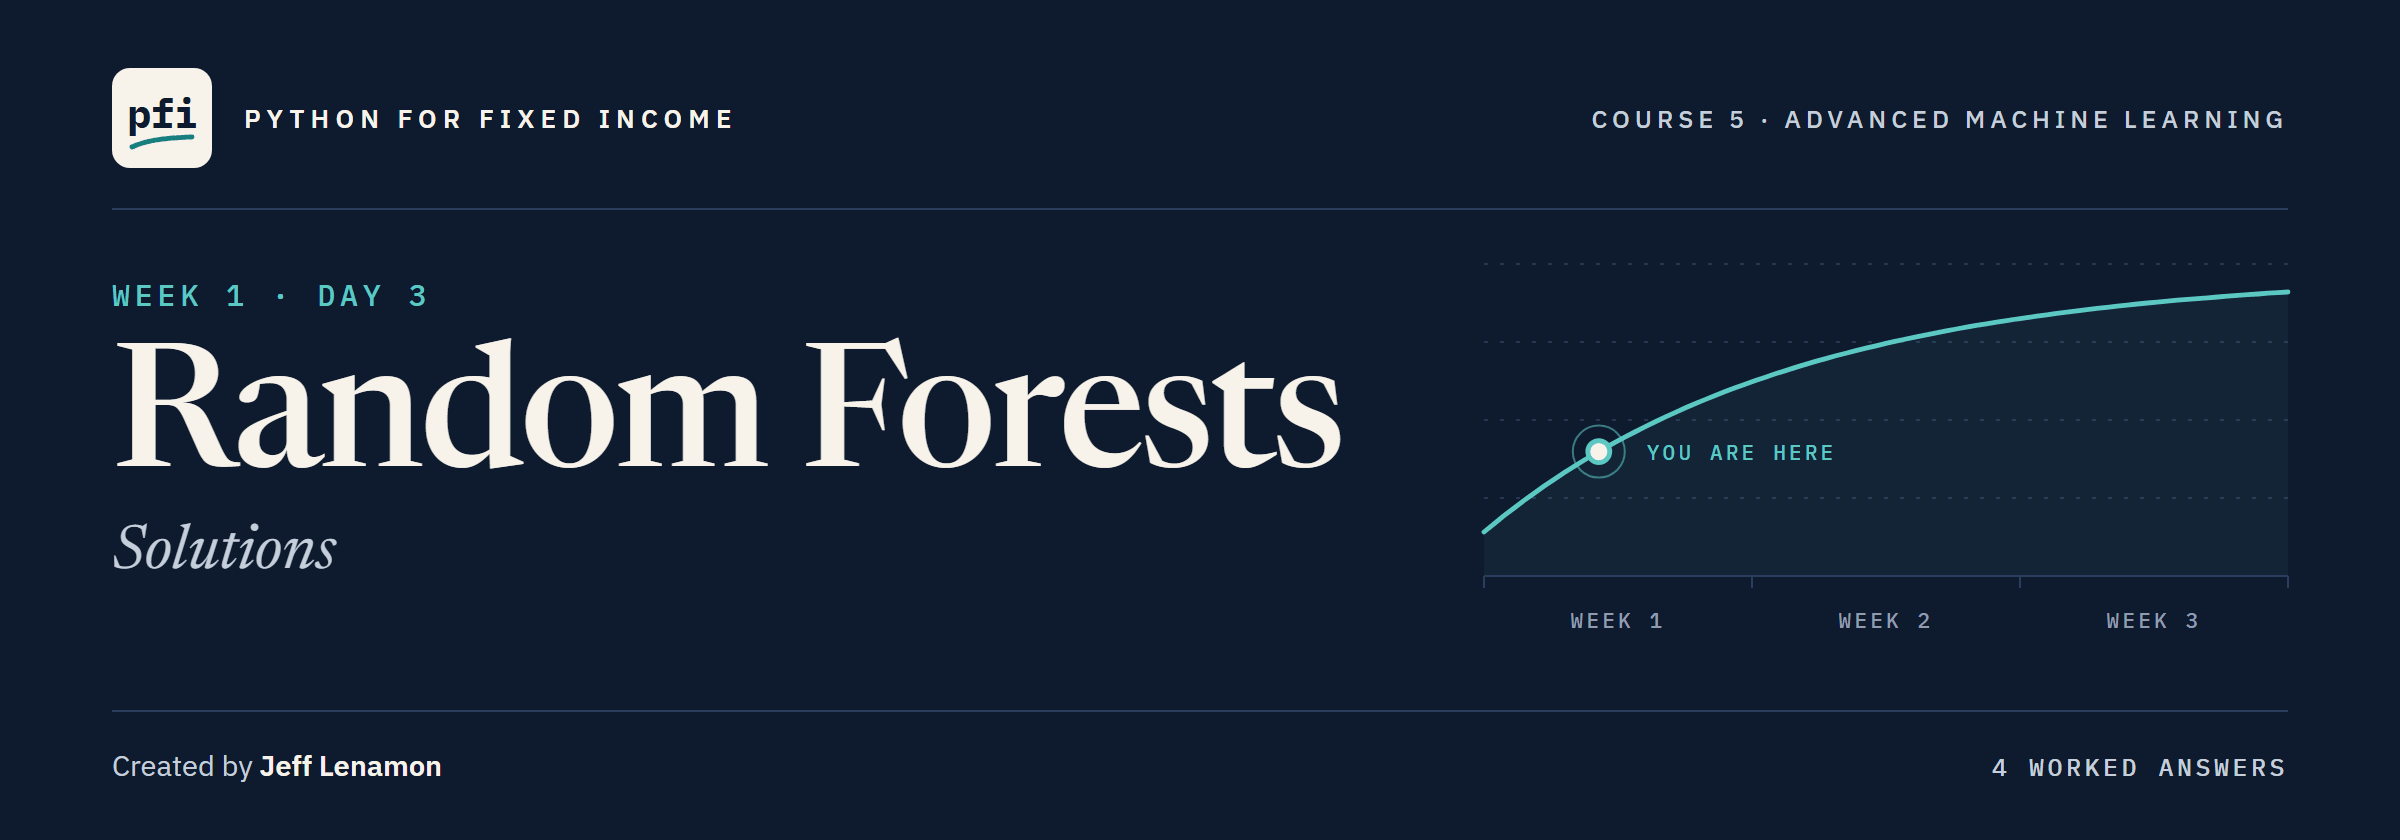

# Random Forests: Solutions

Week 1, Day 3. The full notebook with every exercise worked. Try each one yourself first.

**Data:** `credit_card_default.csv`, 30,000 card accounts in Taiwan in 2005: **real**, UCI Machine Learning Repository dataset 350, CC BY 4.0. Citation: Yeh, I. (2009). Default of Credit Card Clients [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C55S3H.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05_advanced_ml/week1/day3/03_random_forests_solutions.ipynb)

# Problem Statement

## Business Context

Day 2's bag of trees, with leaves chosen out of bag, reached a validation ROC AUC of 0.7837, past Course 4's pruned tree.
Yet all its members asked `PAY_0` first, and Day 2 closed by asking for members that differ more without getting weaker.
A random forest is the standard next step: it changes what each tree may ask at every split.
The desk wants to know what that changes, and which of the forest's settings matter.
Settings are chosen out of bag inside the 18,000 training rows; the validation rows only report.
The accounts are real, from Taiwan in 2005, so they describe consumer credit there and then, not US credit today.
The four person columns are never features, because a model that used them would sort people by them.

## Objectives

Fit a random forest with scikit-learn and read the question each of its trees asks first.
Measure how strong a forest's trees are and how much they agree, sweep the column count and the leaf size, and map every forest by its trees.
Choose the settings out of bag, report the chosen forest on validation rows, watch its score settle as trees are added, and fit extremely randomized trees beside it.

## Data Dictionary

`credit_card_default.csv`, one row per account:

1. `LIMIT_BAL`: credit limit, NT dollars
2. `PAY_0`, `PAY_2` to `PAY_6`: repayment status, September back to April 2005, where -1 is paid on time, 1 to 9 is months late, and -2 and 0 are undocumented (used as numbers, a modelling choice, as in Course 4)
3. `BILL_AMT1` to `BILL_AMT6`: the bill, NT dollars, September back to April
4. `PAY_AMT1` to `PAY_AMT6`: the amount paid, NT dollars, September back to April
5. `default payment next month`: 1 if the account defaulted the following month, **the target**
6. `ID`, `SEX`, `EDUCATION`, `MARRIAGE`, `AGE`: never used

# Setting Up

## Course Setup

Run this cell and move on: it fixes the seed and finds the course data.

In [1]:
# today's setup: the thread settings, the seed, and where the course data lives
import os
from pathlib import Path

# one thread for the maths libraries, so every run prints the same last digits (this must run before numpy is imported)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

# the seed: one number for every random choice, so every run makes the same choices
SEED = 42

# the course data: the repo's data folder on your machine, GitHub in Colab
DATA = "../../../data/"
if not Path(DATA + "benchmark.csv").exists():
    DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"

## Importing the Libraries

In [2]:
# to load and work with the data
import numpy as np
import pandas as pd

# to draw charts, still and interactive
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# to split the accounts
from sklearn.model_selection import train_test_split

# a single tree, a bag of trees, and two kinds of forest
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier, ExtraTreesClassifier

# to score a model's outputs and its flags
from sklearn.metrics import roc_auc_score, average_precision_score, accuracy_score, recall_score, precision_score
from sklearn.metrics import f1_score, confusion_matrix

# one look for every chart, and four decimals in every table
sns.set_theme(style="whitegrid")
sns.set_palette("colorblind")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.float_format", "{:.4f}".format)

# one colour for each of the four cells of a confusion matrix, as in Course 4's Day 7
CELL_COLOURS = {"TN": "#56B4E9", "FP": "#DE8F05", "FN": "#D55E00", "TP": "#0173B2"}

# Loading the Data

## Reading the Card File

In [3]:
# the 30,000 accounts; the target's name has spaces, so we keep it in a variable
card = pd.read_csv(DATA + "credit_card_default.csv")
TARGET = "default payment next month"

# every column except the ID, the four person columns and the target
X = card.drop(columns=["ID", "SEX", "EDUCATION", "MARRIAGE", "AGE", TARGET])
y = card[TARGET]
FEATURES = list(X.columns)
print(len(FEATURES), "features")

19 features


## Checking the Shape and the Default Share

In [4]:
# rows and columns, and how many accounts defaulted
print(card.shape)
print("Defaults:", y.sum(), " Share:", round(y.mean() * 100, 2), "percent")

(30000, 25)
Defaults: 6636  Share: 22.12 percent


**The file Course 4 used, unchanged.**

# Data Preparation for Modeling

## Course 4's Split

In [5]:
# Course 4's split: a fifth of the accounts to test, then a quarter of the rest to validation, defaults spread evenly
X_rest, X_test, y_rest, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
X_train, X_valid, y_train, y_valid = train_test_split(X_rest, y_rest, test_size=0.25, stratify=y_rest, random_state=SEED)
print("Training:", len(X_train), " Validation:", len(X_valid), " Test:", len(X_test))

Training: 18000  Validation: 6000  Test: 6000


The same accounts as Course 4 and Days 1 and 2.

Every score below is on the validation rows; Course 5 chooses nothing on them and never scores the test rows.

**Training rows fit and choose, validation rows report, test rows stay closed.**

# Where Bagging Left Off

## Day 2's Bag, Refit

`auc` is Day 1's: the ROC AUC of a model's outputs on some rows.

In [6]:
# ROC AUC of a model's outputs on some rows (Day 1's)
def auc(model, rows, target):
    return roc_auc_score(target, model.predict_proba(rows)[:, 1])

# Day 2's bag: 200 full trees, each on its own bootstrap sample, scored out of bag too
bag = BaggingClassifier(estimator=DecisionTreeClassifier(random_state=SEED), n_estimators=200, oob_score=True,
                        random_state=SEED, n_jobs=1).fit(X_train, y_train)
print("Validation ROC AUC:", round(auc(bag, X_valid, y_valid), 4))

Validation ROC AUC: 0.7621


## How Alike Its Members Are

Day 2 measured how alike two members are as the correlation of their outputs on the validation rows.
A tree's **strength** here is its own ROC AUC on the validation rows; a forest's strength is the average over its trees.
These two numbers describe the trees; they choose nothing.

In [7]:
# each tree's output for every validation account, one column per tree (members are fitted on plain arrays, Day 2)
def tree_outputs(model):
    return np.column_stack([tree.predict_proba(X_valid.to_numpy())[:, 1] for tree in model.estimators_])

# how alike a model's trees are (the correlation of every pair, Day 2's) and how strong (their average ROC AUC)
def describe_forest(model):
    outputs = tree_outputs(model)
    pairs = np.triu_indices(outputs.shape[1], k=1)
    correlations = np.corrcoef(outputs.T)[pairs]
    strength = np.mean([roc_auc_score(y_valid, outputs[:, j]) for j in range(outputs.shape[1])])
    return correlations, strength

In [8]:
# the bag's members: their mean pair correlation and their strength
bag_correlations, bag_strength = describe_forest(bag)
print("Pairs:", len(bag_correlations), " Mean correlation:", round(bag_correlations.mean(), 4))
print("Strength:", round(bag_strength, 4))

Pairs: 19900  Mean correlation: 0.2567
Strength: 0.6161


## The First Question

In [9]:
# the column each member asks at its root (Day 1's tree_.feature[0])
bag_first = pd.Series([FEATURES[tree.tree_.feature[0]] for tree in bag.estimators_])
bag_first.value_counts()

PAY_0    200
Name: count, dtype: int64

**Every member opens with the same question, and the members agree at 0.2567. A forest makes them ask different ones.**

# A Random Handful of Columns

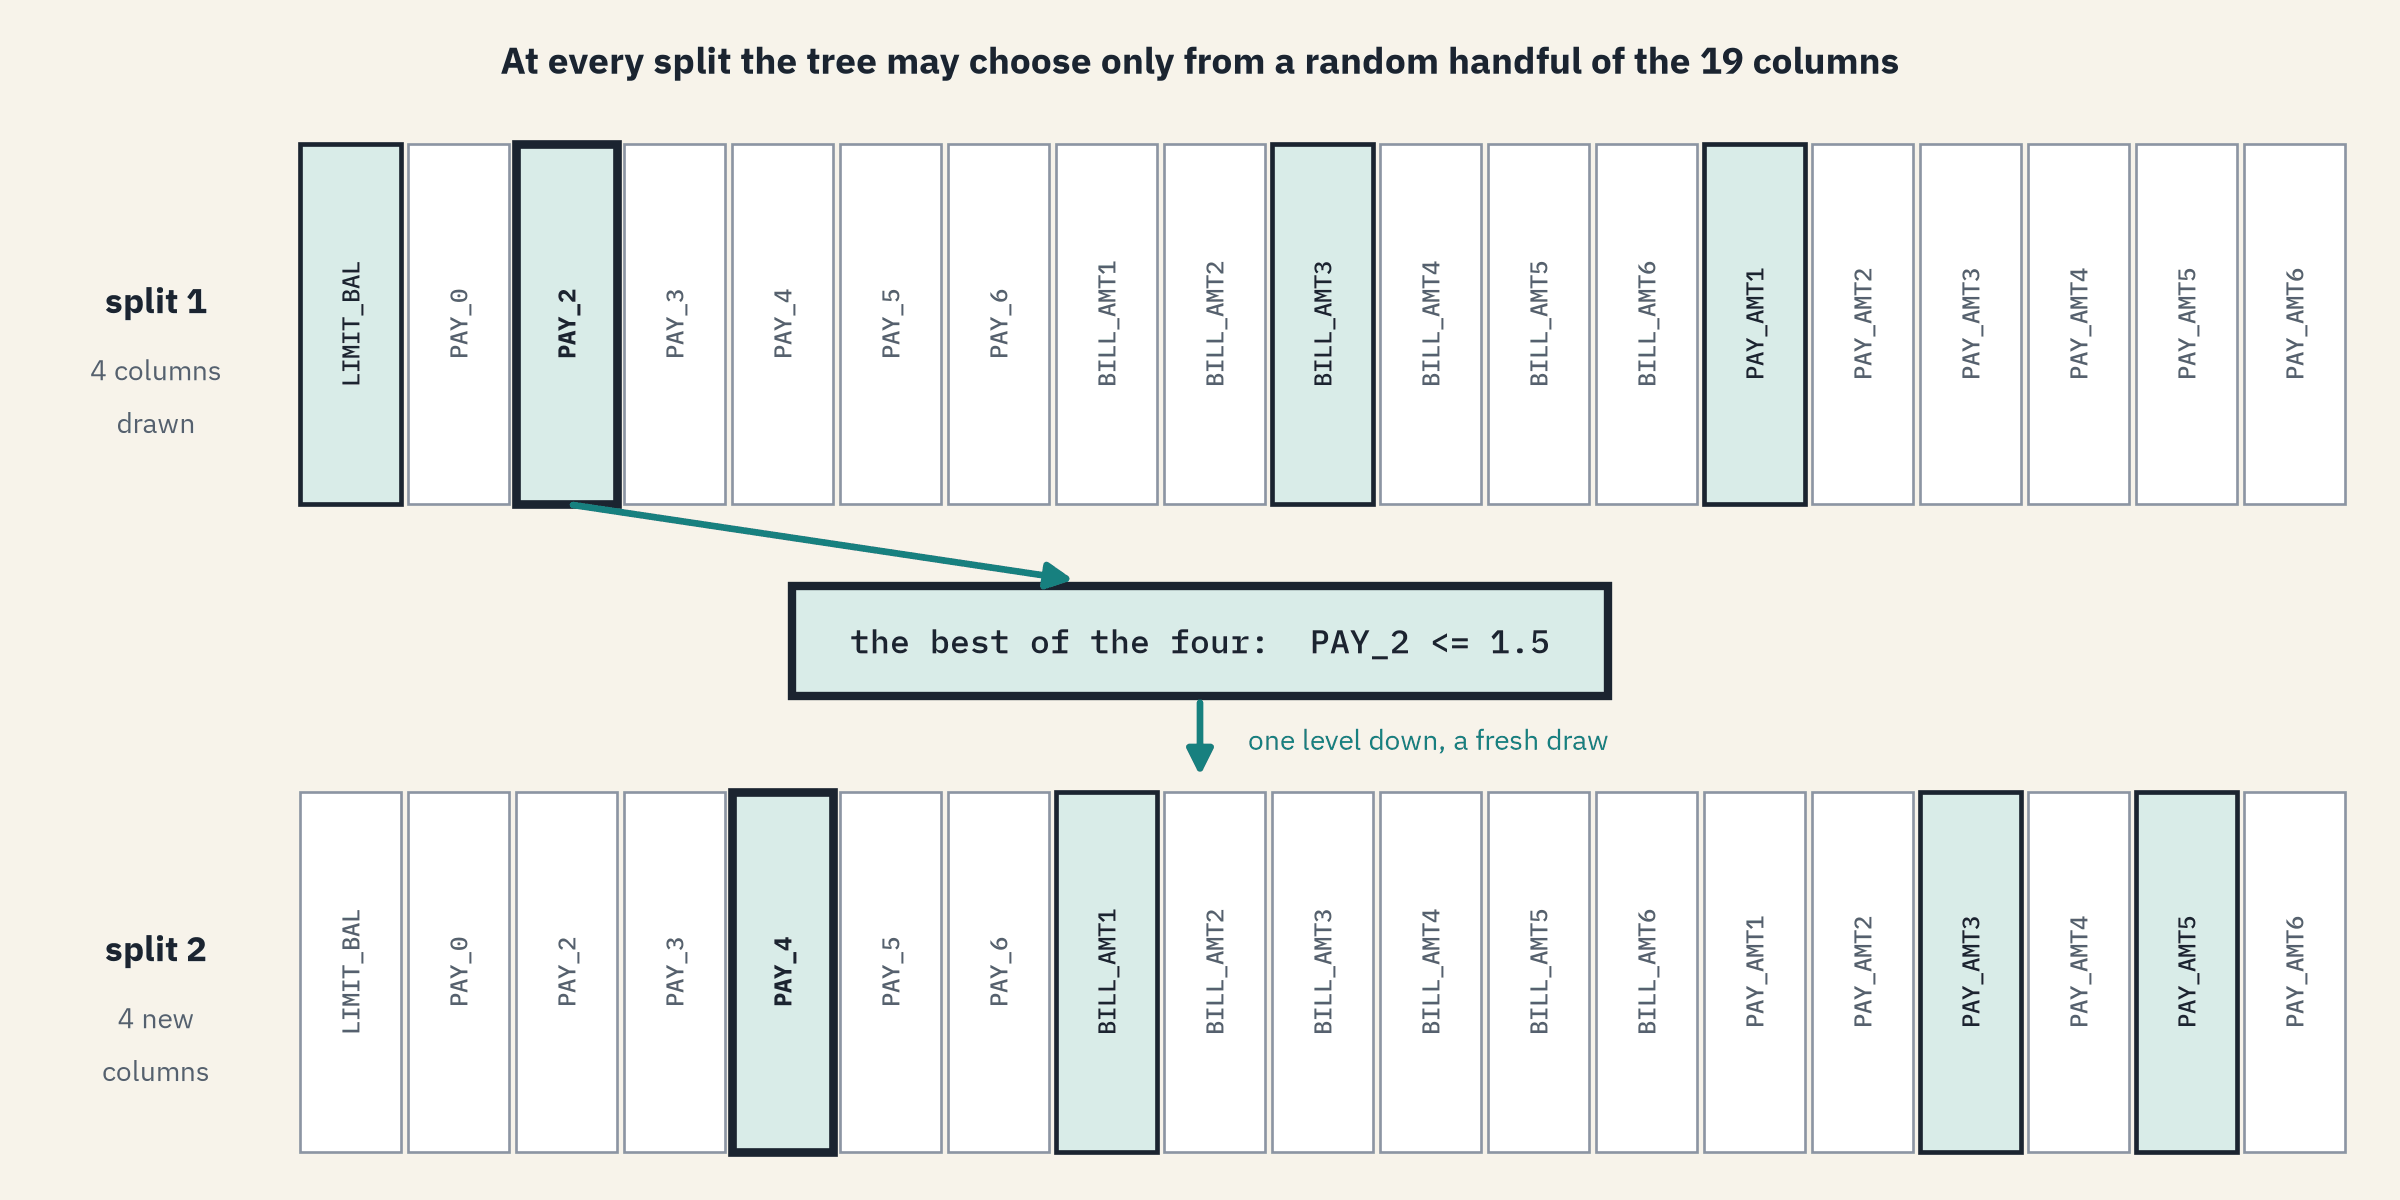

A **random forest** is bagging with one change: at every split, a tree may choose only from a random handful of the columns, drawn afresh at that split.
`max_features` sets the handful; its default, `"sqrt"`, offers the whole part of the square root of the column count, 4 of our 19.
`n_estimators` is the number of trees, as in Day 2's bag.

> STORY: Leo Breiman published "Random Forests" in Machine Learning, volume 45, issue 1, pages 5 to 32, in October 2001, five years after his paper on bagging. Source: https://api.crossref.org/works/10.1023/A:1010933404324

## A Forest in One Call

In [10]:
# a random forest: 200 trees, every split choosing from a random handful of columns (the default, "sqrt")
forest = RandomForestClassifier(n_estimators=200, oob_score=True, random_state=SEED, n_jobs=1).fit(X_train, y_train)
print("Columns offered at each split:", forest.estimators_[0].max_features_)

Columns offered at each split: 4


**Predict 1**

The bag's 200 trees score 0.7621 on the validation rows.

Q. What does the forest of 200 trees score? Write down a number.

## The Forest on the Validation Rows

In [11]:
# the forest's ROC AUC and average precision on the validation rows
forest_valid = forest.predict_proba(X_valid)[:, 1]
print("ROC AUC:", round(roc_auc_score(y_valid, forest_valid), 4))
print("Average precision:", round(average_precision_score(y_valid, forest_valid), 4))

ROC AUC: 0.7604
Average precision: 0.5149


0.7604, 0.0017 below the bag: the handful of columns did not lift the score.

The trees are as many and as deep as the bag's; only the columns they may ask changed.

**Predict 2**

Q. Every bag member asked `PAY_0` first. How many of the forest's 200 trees do? Write down a number.

## What the Forest's Trees Ask First

In [12]:
# the column each of the forest's trees asks at its root
forest_first = pd.Series([FEATURES[tree.tree_.feature[0]] for tree in forest.estimators_])
forest_first.value_counts()

PAY_2        38
PAY_0        36
PAY_4        27
PAY_6        25
PAY_3        23
PAY_5        20
PAY_AMT1      9
LIMIT_BAL     7
PAY_AMT2      4
PAY_AMT6      4
PAY_AMT3      4
PAY_AMT5      2
PAY_AMT4      1
Name: count, dtype: int64

`subplot_kw={"projection": "polar"}` gives each panel round axes, as `projection="3d"` gave Course 4 its 3D ones.
`ax.bar` then takes an angle in radians for each bar (`2 * np.pi` is a full turn), so each column gets a petal of its own.

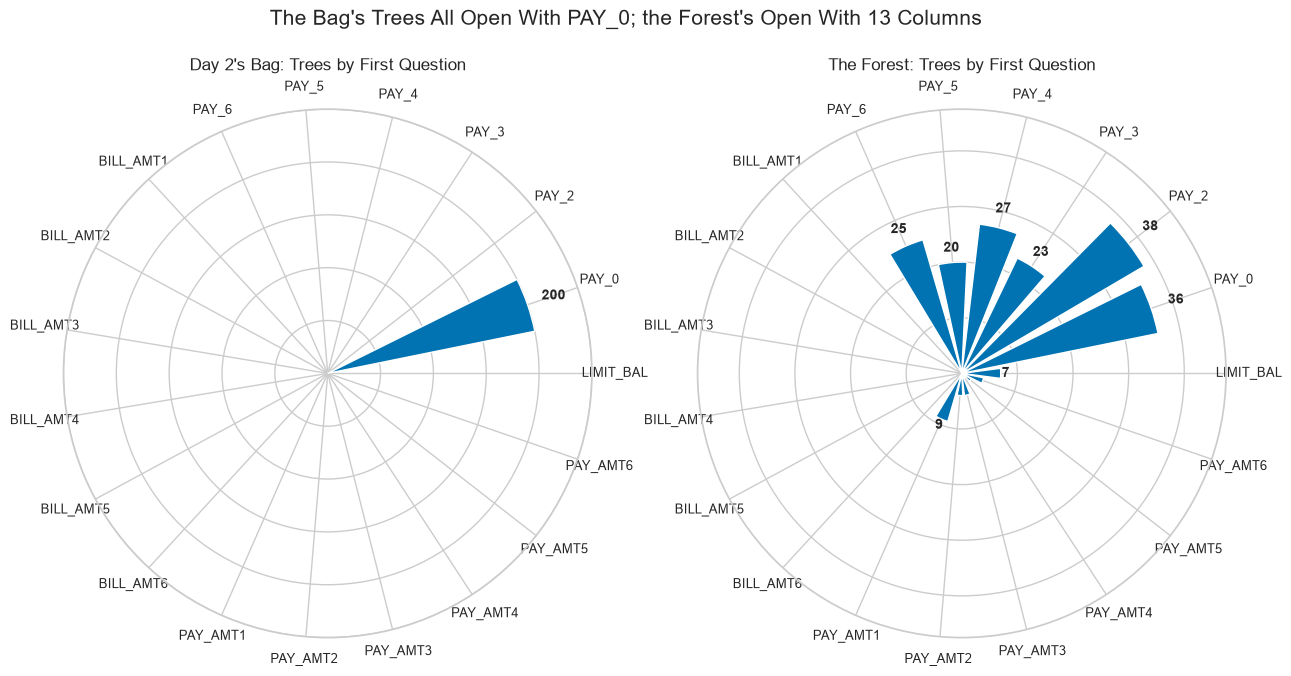

In [13]:
# a polar rose: one petal per column, as long as the number of trees that ask it first, counts of 5 or more written on
angles = np.linspace(0, 2 * np.pi, len(FEATURES), endpoint=False)
fig, axes = plt.subplots(1, 2, figsize=(15, 7.5), subplot_kw={"projection": "polar"})
for ax, first, name in zip(axes, [bag_first, forest_first], ["Day 2's Bag", "The Forest"]):
    counts = first.value_counts().reindex(FEATURES, fill_value=0)
    ax.bar(angles, counts, width=0.26, color=np.where(counts > 0, "C0", "lightgray"))
    for angle, count in zip(angles[counts >= 5], counts[counts >= 5]):
        ax.text(angle, count * 1.13, str(count), ha="center", va="center", fontsize=10, weight="bold")
    ax.set_xticks(angles, FEATURES, fontsize=9)
    ax.set(ylim=(0, counts.max() * 1.25), yticklabels=[])
    ax.set_title(name + ": Trees by First Question", pad=28)
fig.suptitle("The Bag's Trees All Open With PAY_0; the Forest's Open With 13 Columns", fontsize=15)
plt.show()

36 of 200 trees ask `PAY_0` first, and 169 open with one of the six status columns.

A root is offered `PAY_0` with chance 4/19, about 21 percent, so in about 42 of 200 trees: when it is offered, it usually wins.

The trees open with 13 columns, against one for the bag.

**Thirteen first questions, yet the forest scores 0.0017 below the bag. The next section finds out why different questions gave much the same answers.**

# Why the Trees Still Agree

## The Status Columns Are Cousins

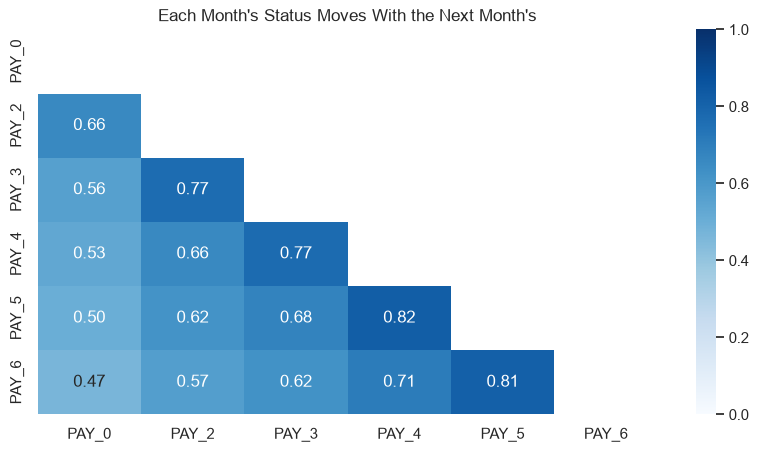

In [14]:
# correlations among the six repayment status columns on the training rows, the lower triangle only
status = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
status_corr = X_train[status].corr()
sns.heatmap(status_corr, mask=np.triu(np.ones_like(status_corr, dtype=bool)), annot=True, fmt=".2f", cmap="Blues",
            vmin=0, vmax=1)
plt.grid(False)
plt.title("Each Month's Status Moves With the Next Month's")
plt.show()

`PAY_0` and `PAY_2` correlate at 0.66, and each later pair of neighbouring months at 0.77 to 0.82.

A tree denied `PAY_0` at its root usually takes another month: the name of the question changes more than its answer.

## How Alike the Forest's Trees Are

In [15]:
# the forest's trees: their mean pair correlation and their strength, beside the bag's
forest_correlations, forest_strength = describe_forest(forest)
print("Mean correlation:", round(forest_correlations.mean(), 4), " Bag:", round(bag_correlations.mean(), 4))
print("Strength:", round(forest_strength, 4), " Bag:", round(bag_strength, 4))

Mean correlation: 0.2487  Bag: 0.2567
Strength: 0.6147  Bag: 0.6161


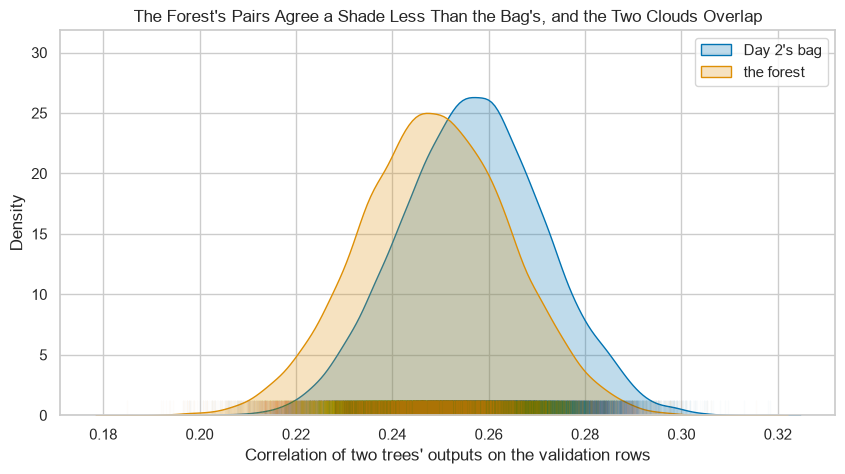

In [16]:
# the 19,900 pair correlations of each model as a density curve, with a rug of the pairs beneath
sns.kdeplot(bag_correlations, fill=True, label="Day 2's bag")
sns.kdeplot(forest_correlations, fill=True, label="the forest")
sns.rugplot(bag_correlations, height=0.04, alpha=0.02, color="C0")
sns.rugplot(forest_correlations, height=0.04, alpha=0.02, color="C1")
plt.xlabel("Correlation of two trees' outputs on the validation rows")
plt.ylabel("Density")
plt.title("The Forest's Pairs Agree a Shade Less Than the Bag's, and the Two Clouds Overlap")
plt.legend()
plt.show()

The forest's trees agree at 0.2487 against the bag's 0.2567, and are a shade weaker, 0.6147 against 0.6161.

The two clouds of 19,900 pairs overlap almost entirely.

### Interpretation of the Small Change

In [17]:
# how many of a full tree's outputs are exactly 0 or 1, and both models on their own training rows
forest_outputs = tree_outputs(forest)
print("Tree outputs at exactly 0 or 1:", round(((forest_outputs == 0) | (forest_outputs == 1)).mean() * 100, 1), "percent")
print("Training ROC AUC, bag:", round(auc(bag, X_train, y_train), 4), " forest:", round(auc(forest, X_train, y_train), 4))

Tree outputs at exactly 0 or 1: 97.8 percent
Training ROC AUC, bag: 0.9996  forest: 0.9996


97.8 percent of a full tree's outputs are exactly 0 or 1, and both models score 0.9996 on their own training rows.

Full trees memorise their rows all the way down, so whatever the first question, each tree ends in tiny leaves that copy its own sample.

**Hiding columns changed the trees' first question, not their answers. The other lever is the trees themselves: stop them memorising and watch strength and agreement.**

# Strength Against Agreement

`min_samples_leaf` sets the fewest training accounts a leaf may hold, the setting Day 2 chose out of bag for its bag.
The grid crosses five column counts with Day 2's six leaf sizes: 30 forests of 50 trees, each scored out of bag as Day 2 did, with `roc_auc_score` on `oob_decision_function_`.
`max_features=19` offers every column at every split, so that column of the grid is a bag.

**Predict 3**

Full trees agree at about 0.25.

Q. Take the forest with 4 columns per split and leaves of at least 100 accounts. What is the mean correlation between its trees? Write down a number.

## Thirty Forests

In [18]:
# 30 forests of 50 trees: for each, how alike and how strong its trees are, and its out-of-bag ROC AUC
rows = []
for columns in [1, 2, 4, 8, 19]:
    for leaf in [1, 3, 10, 30, 100, 300]:
        model = RandomForestClassifier(n_estimators=50, max_features=columns, min_samples_leaf=leaf, oob_score=True,
                                       random_state=SEED, n_jobs=1).fit(X_train, y_train)
        correlations, strength = describe_forest(model)
        rows.append([columns, leaf, correlations.mean(), strength, roc_auc_score(y_train, model.oob_decision_function_[:, 1])])
grid = pd.DataFrame(rows, columns=["max_features", "min_samples_leaf", "correlation", "strength", "oob_roc_auc"])

In [19]:
# the mean correlation between trees: one row per leaf size, one column per column count
grid.pivot(index="min_samples_leaf", columns="max_features", values="correlation")

max_features,1,2,4,8,19
min_samples_leaf,,,,,
1,0.2141,0.2333,0.2491,0.2558,0.2583
3,0.3588,0.3483,0.3417,0.3402,0.3339
10,0.5219,0.5193,0.5233,0.5169,0.4990
30,0.6174,0.6529,0.6911,0.7063,0.6906
100,0.6329,0.7202,0.7885,0.8449,0.8550
300,0.5555,0.6757,0.7718,0.8667,0.9345


In [20]:
# the strength of the trees, laid out the same way
grid.pivot(index="min_samples_leaf", columns="max_features", values="strength")

max_features,1,2,4,8,19
min_samples_leaf,,,,,
1,0.6057,0.6118,0.6154,0.6178,0.6170
3,0.6646,0.6624,0.6585,0.6541,0.6501
10,0.6993,0.7039,0.7062,0.7016,0.6973
30,0.7140,0.7265,0.7351,0.7372,0.7331
100,0.7109,0.7326,0.7460,0.7544,0.7553
300,0.6898,0.7163,0.7395,0.7517,0.7596


With 4 columns and 100-account leaves the trees agree at 0.7885, three times as much as full trees, and score 0.7460 on average against 0.6154.

Down each column, bigger leaves make the trees stronger and more alike up to leaves of 30 accounts; past 100, only the 19-column bag keeps climbing on both.

## Every Forest on One Map

A **carpet plot** draws a grid of two settings as a net: each forest is a point, and lines join the forests that share a setting.

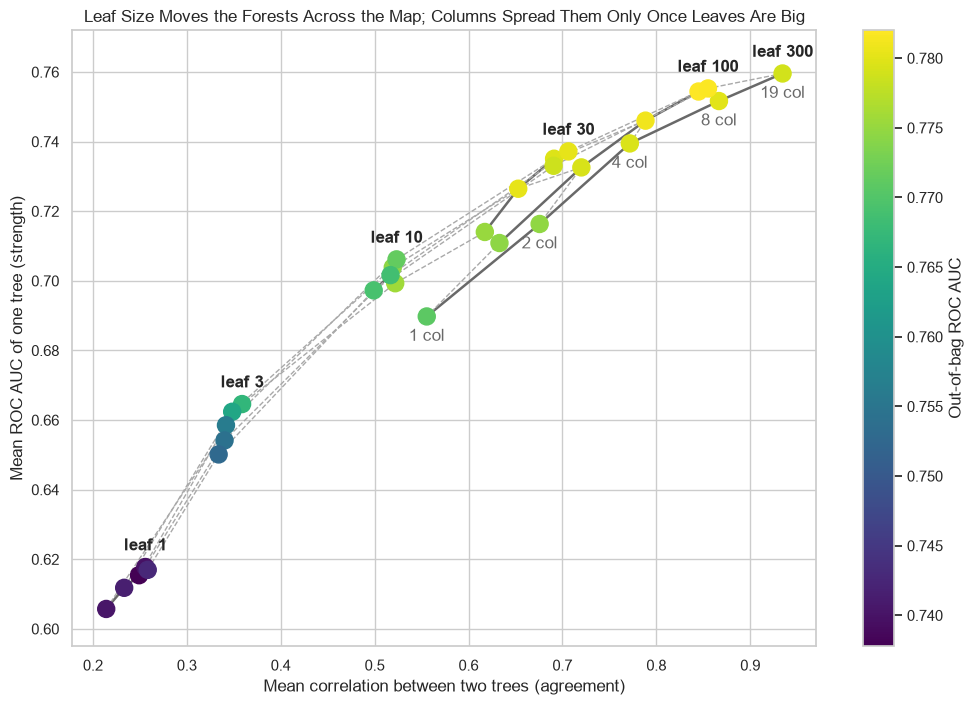

In [21]:
# each forest at (agreement, strength), coloured by its out-of-bag ROC AUC; solid lines join equal leaves, dashed equal columns
fig, ax = plt.subplots(figsize=(12, 8))
for leaf in [1, 3, 10, 30, 100, 300]:
    same = grid[grid["min_samples_leaf"] == leaf]
    top = same.loc[same["strength"].idxmax()]
    ax.plot(same["correlation"], same["strength"], color="dimgray", linewidth=1.8)
    ax.annotate(f"leaf {leaf}", (top["correlation"], top["strength"]), xytext=(0, 12), textcoords="offset points", ha="center", weight="bold")
for columns in [1, 2, 4, 8, 19]:
    same = grid[grid["max_features"] == columns]
    ax.plot(same["correlation"], same["strength"], color="darkgray", linestyle="--", linewidth=1)
    ax.text(same["correlation"].iloc[-1], same["strength"].iloc[-1] - 0.007, f"{columns} col", ha="center", color="dimgray")
points = ax.scatter(grid["correlation"], grid["strength"], c=grid["oob_roc_auc"], cmap="viridis", s=150, zorder=3)
fig.colorbar(points, label="Out-of-bag ROC AUC")
ax.set(xlabel="Mean correlation between two trees (agreement)", ylabel="Mean ROC AUC of one tree (strength)", ylim=(0.595, 0.772),
       title="Leaf Size Moves the Forests Across the Map; Columns Spread Them Only Once Leaves Are Big")
plt.show()

The leaf-1 forests sit together bottom left, whatever the column count.

Each bigger leaf size up to 30 accounts carries the whole row of forests up and right: stronger trees that agree more.

At 100-account leaves the column count opens up: 1 column gives agreement 0.6329 and strength 0.7109, 19 columns 0.8550 and 0.7553.

The brightest points, the best out of bag, are among the strongest forests, never among the least alike.

### Interpretation of Strength and Agreement

An average cancels what its trees do not share and keeps what they share, right answers included.

So the correlation counts agreement on the pattern as well as on the noise: leafy trees agree more because they all find the same pattern.

A forest scores well when its trees are strong and agree no more than their strength requires.

On this file bigger leaves buy strength cheaply, and fewer columns buy disagreement dearly.

**Stronger trees beat more different trees on this file. Choose the two settings out of bag.**

# Choosing the Forest Out of Bag

## The Thirty Scores Side by Side

In a **parallel coordinates** chart each forest is one line crossing an axis per number.
Drag along the out-of-bag axis to keep only the best forests and see which settings they share.

In [22]:
# one line per forest across five axes, coloured by its out-of-bag ROC AUC
fig = px.parallel_coordinates(grid, color="oob_roc_auc", color_continuous_scale="Viridis",
                              labels={"max_features": "Columns per split", "min_samples_leaf": "Leaf size",
                                      "correlation": "Correlation", "strength": "Strength", "oob_roc_auc": "Out of bag"},
                              title="Thirty Forests: Drag on an Axis to Keep the Lines That Pass Through It")
fig.show()

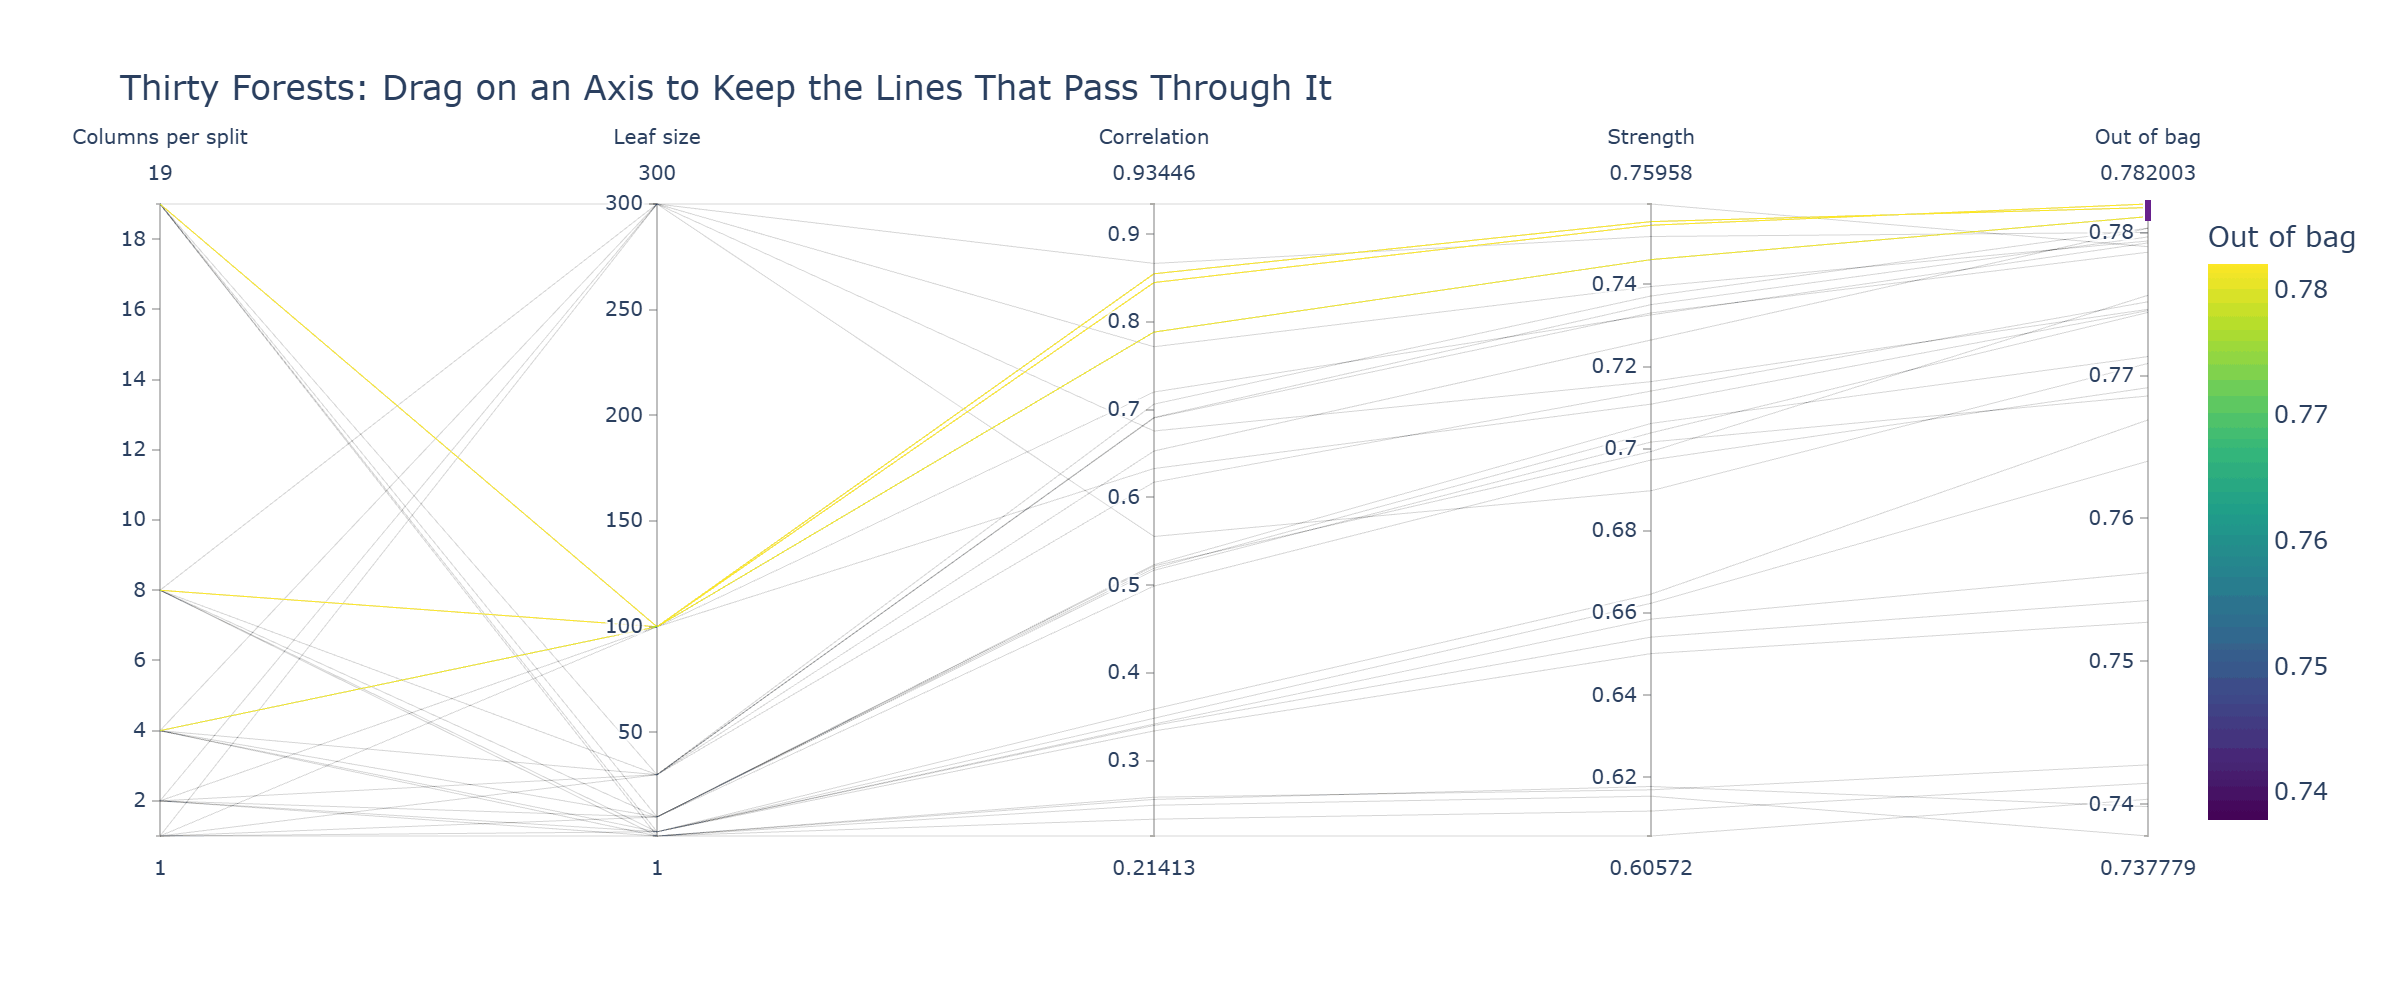

In [23]:
# the out-of-bag ROC AUC of the 30 forests, and the best of them
print(grid.pivot(index="min_samples_leaf", columns="max_features", values="oob_roc_auc"))
grid.loc[grid["oob_roc_auc"].idxmax()]

max_features         1      2      4      8      19
min_samples_leaf                                   
1                0.7404 0.7415 0.7378 0.7398 0.7428
3                0.7669 0.7640 0.7562 0.7543 0.7527
10               0.7756 0.7744 0.7713 0.7686 0.7691
30               0.7752 0.7803 0.7797 0.7803 0.7786
100              0.7745 0.7793 0.7811 0.7820 0.7818
300              0.7708 0.7746 0.7794 0.7800 0.7790


max_features         8.0000
min_samples_leaf   100.0000
correlation          0.8449
strength             0.7544
oob_roc_auc          0.7820
Name: 22, dtype: float64

The best forest out of bag has 8 columns and 100-account leaves, at 0.7820; 19 columns score 0.7818 and the default 4 score 0.7811, 0.0009 behind.

Leaves of 300 score below leaves of 100 at every column count.

**We take 8 columns per split and leaves of at least 100 accounts; the default 4 would do almost as well.**

## Which Setting Matters

In [24]:
# the chosen settings with 25 trees and with 200, each scored out of bag
small = RandomForestClassifier(n_estimators=25, max_features=8, min_samples_leaf=100, oob_score=True,
                               random_state=SEED, n_jobs=1).fit(X_train, y_train)
chosen = RandomForestClassifier(n_estimators=200, max_features=8, min_samples_leaf=100, oob_score=True,
                                random_state=SEED, n_jobs=1).fit(X_train, y_train)
small_oob = roc_auc_score(y_train, small.oob_decision_function_[:, 1])
chosen_oob = roc_auc_score(y_train, chosen.oob_decision_function_[:, 1])
print("Out-of-bag ROC AUC, 25 trees:", round(small_oob, 4), " 200 trees:", round(chosen_oob, 4))

Out-of-bag ROC AUC, 25 trees: 0.7786  200 trees: 0.7834


A **tornado chart** draws one bar per setting, from the lowest to the highest score as that setting moves while the others stay at the chosen values.

In [25]:
# the out-of-bag range as each setting moves: leaves and columns from the 50-tree grid, trees from the two fits above
leaf_moves = grid[grid["max_features"] == 8]["oob_roc_auc"]
column_moves = grid[grid["min_samples_leaf"] == 100]["oob_roc_auc"]
ranges = pd.DataFrame({"low": [leaf_moves.min(), column_moves.min(), small_oob],
                       "high": [leaf_moves.max(), column_moves.max(), chosen_oob]},
                      index=["leaf size, 1 to 300", "columns per split, 1 to 19", "trees, 25 to 200"])
ranges["range"] = ranges["high"] - ranges["low"]
ranges

,low,high,range
"leaf size, 1 to 300",0.7398,0.7820,0.0422
"columns per split, 1 to 19",0.7745,0.7820,0.0075
"trees, 25 to 200",0.7786,0.7834,0.0048


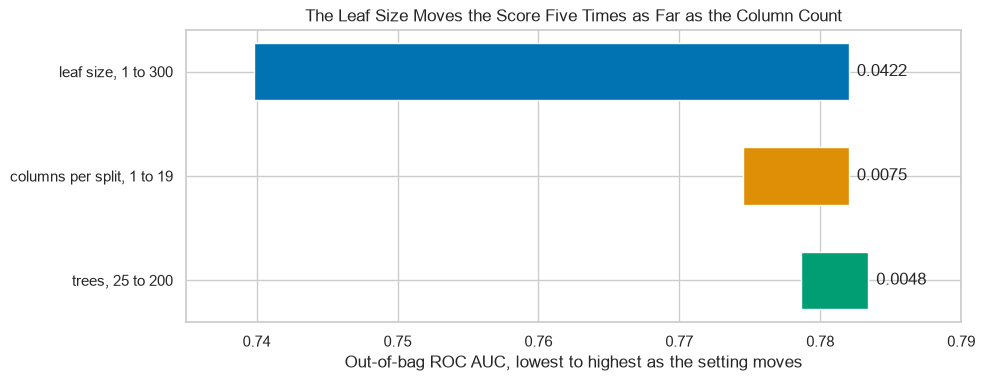

In [26]:
# the tornado: one bar per setting from its low to its high, the widest on top
fig, ax = plt.subplots(figsize=(10, 3.8))
bars = ax.barh(ranges.index, ranges["range"], left=ranges["low"], color=["C0", "C1", "C2"], height=0.55)
ax.bar_label(bars, labels=[f"{r:.4f}" for r in ranges["range"]], padding=6)
ax.invert_yaxis()
ax.set_xlim(0.735, 0.79)
ax.set_xlabel("Out-of-bag ROC AUC, lowest to highest as the setting moves")
ax.set_title("The Leaf Size Moves the Score Five Times as Far as the Column Count")
plt.show()

The leaf size moves the out-of-bag score by 0.0422, the column count by 0.0075, and the trees from 25 to 200 by 0.0048.

## The Chosen Forest on the Validation Rows

`model_performance_classification` is Course 4's Day 8's, with ROC AUC first, and `draw_confusion` is Course 4's Day 7's, each repeated as one cell.

In [27]:
# flag at or above the threshold, then the ROC AUC and four measures of the flags in one row
def model_performance_classification(model, predictors, target, threshold=0.5):
    flags = (model.predict_proba(predictors)[:, 1] >= threshold).astype(int)
    return pd.DataFrame({
        "ROC AUC": [roc_auc_score(target, model.predict_proba(predictors)[:, 1])],
        "Accuracy": [accuracy_score(target, flags)],
        "Recall": [recall_score(target, flags, zero_division=0)],
        "Precision": [precision_score(target, flags, zero_division=0)],
        "F1": [f1_score(target, flags, zero_division=0)],
    })

In [28]:
# the chosen forest on the accounts it was fitted on, and on the validation accounts, at 0.5
train_valid = pd.concat([model_performance_classification(chosen, X_train, y_train).T,
                         model_performance_classification(chosen, X_valid, y_valid).T], axis=1)
train_valid.columns = ["training", "validation"]
train_valid

,training,validation
ROC AUC,0.8204,0.7844
Accuracy,0.8231,0.8192
Recall,0.3616,0.3459
Precision,0.6916,0.6790
F1,0.4749,0.4583


In [29]:
# draw a confusion matrix: each cell in its own colour, with its name, its count and its share of the accounts
def draw_confusion(target, flags, ax, title):
    tn, fp, fn, tp = confusion_matrix(target, flags).ravel()
    total = tn + fp + fn + tp
    labels = [[f"TN\n{tn:,}\n{tn / total:.1%}", f"FP\n{fp:,}\n{fp / total:.1%}"],
              [f"FN\n{fn:,}\n{fn / total:.1%}", f"TP\n{tp:,}\n{tp / total:.1%}"]]
    sns.heatmap([[0, 1], [2, 3]], cmap=list(CELL_COLOURS.values()), annot=labels, fmt="", cbar=False, ax=ax, annot_kws={"size": 14},
                xticklabels=["not flagged (0)", "flagged (1)"], yticklabels=["paid (0)", "defaulted (1)"])
    ax.set(xlabel="The flag", ylabel="What happened", title=title)

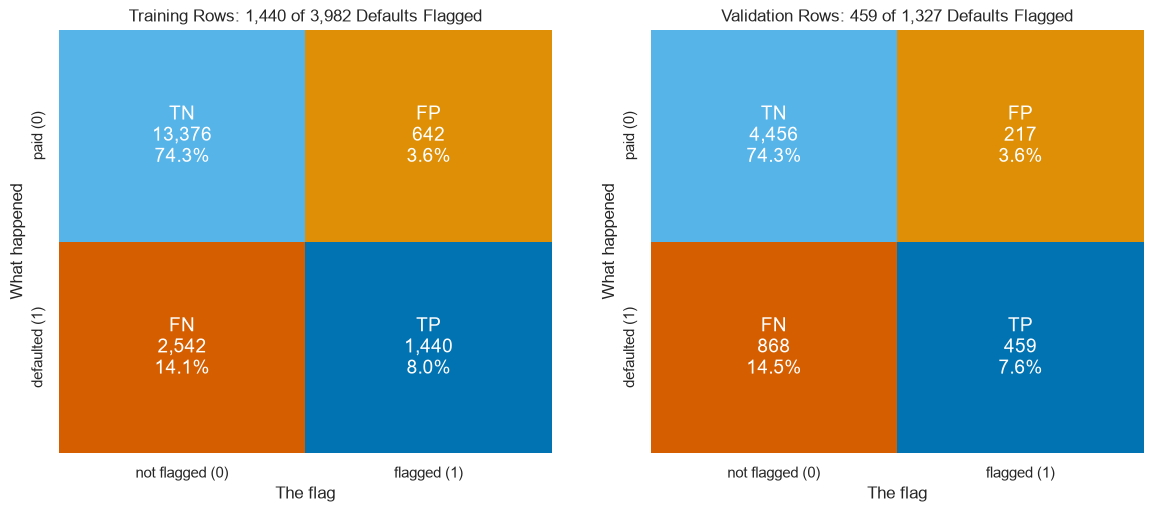

In [30]:
# the chosen forest's flags at 0.5, on the training rows and on the validation rows
fig, (left, right) = plt.subplots(1, 2, figsize=(14, 5.5))
draw_confusion(y_train, chosen.predict(X_train), left, "Training Rows: 1,440 of 3,982 Defaults Flagged")
draw_confusion(y_valid, chosen.predict(X_valid), right, "Validation Rows: 459 of 1,327 Defaults Flagged")
plt.show()

In [31]:
# the size of the chosen forest's trees
print("Leaves:", min(t.get_n_leaves() for t in chosen.estimators_), "to", max(t.get_n_leaves() for t in chosen.estimators_))
print("Depth:", min(t.get_depth() for t in chosen.estimators_), "to", max(t.get_depth() for t in chosen.estimators_))

Leaves: 80 to 92
Depth: 12 to 19


Validation ROC AUC 0.7844, 0.0007 above Day 2's chosen bag at 0.7837.

Training 0.8204 against 0.9996 for full trees, and recall 0.3616 on the training rows against 0.3459 on the validation rows: the chosen forest does not memorise.

Its trees have 80 to 92 leaves and are 12 to 19 questions deep, against thousands of leaves for a full tree.

## How Many Trees It Needs

In [32]:
# ROC AUC of the running average of a forest's first k trees, k = 1 to 200 (Day 2's running average)
def running_auc(model):
    running = tree_outputs(model).cumsum(axis=1) / np.arange(1, len(model.estimators_) + 1)
    return pd.Series([roc_auc_score(y_valid, running[:, k]) for k in range(running.shape[1])], index=range(1, running.shape[1] + 1))

curves = pd.DataFrame({"default forest": running_auc(forest), "chosen forest": running_auc(chosen)})
curves.loc[[1, 25, 200]]

,default forest,chosen forest
1,0.6064,0.7533
25,0.7507,0.7814
200,0.7604,0.7844


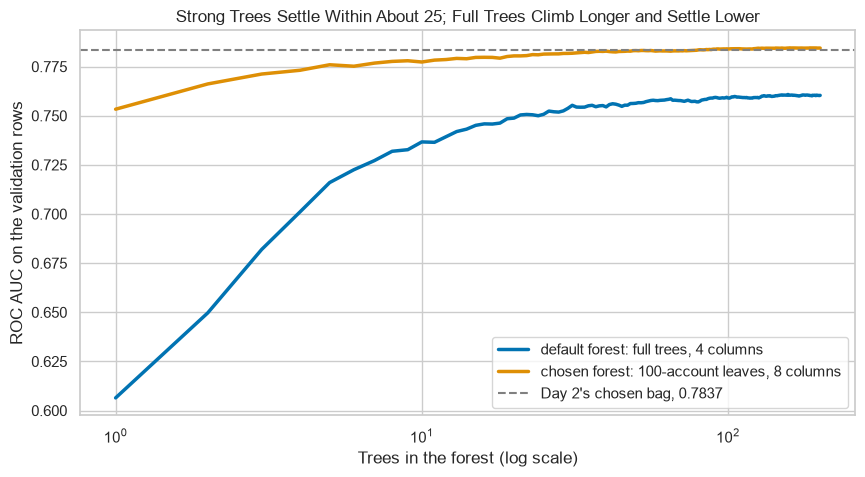

In [33]:
# both forests' scores as trees are added, on a log axis (Day 2's), with Day 2's chosen bag for reference
fig, ax = plt.subplots()
ax.plot(curves.index, curves["default forest"], linewidth=2.5, label="default forest: full trees, 4 columns")
ax.plot(curves.index, curves["chosen forest"], linewidth=2.5, label="chosen forest: 100-account leaves, 8 columns")
ax.axhline(0.7837, color="gray", linestyle="--", label="Day 2's chosen bag, 0.7837")
ax.set_xscale("log")
ax.set(xlabel="Trees in the forest (log scale)", ylabel="ROC AUC on the validation rows")
ax.set_title("Strong Trees Settle Within About 25; Full Trees Climb Longer and Settle Lower")
ax.legend(loc="lower right")
plt.show()

One strong tree scores 0.7533; one full tree 0.6064.

The chosen forest reaches 0.7814 at 25 trees and 0.7844 at 200; the default forest 0.7507 and 0.7604.

Past about 25 strong trees, more trees cost run time and add little.

## The Settings That Shape a Forest

`RandomForestClassifier` takes these settings, among others:

* `n_estimators`, the number of trees: more trees steady the score and cost run time.
* `max_features`, the columns offered at each split: `"sqrt"` (the default), a whole number, a share such as 0.5, or `None` for every column, which makes a bag.
* `min_samples_leaf`, the fewest training accounts a leaf may hold: the setting that moved the score most here.
* `bootstrap` and `max_samples`, whether each tree gets a bootstrap sample and how large, as in Day 2's bag.
* `class_weight="balanced_subsample"`, balanced weights set inside each tree's own sample: the output then becomes the model's score, as Day 2's weighted bag showed.
* `oob_score=True`, which keeps the out-of-bag outputs, read with `roc_auc_score` on `oob_decision_function_`.

**Leaf size first, then enough trees; the column count fine-tunes. One more kind of randomness is left to try.**

# Extremely Randomized Trees

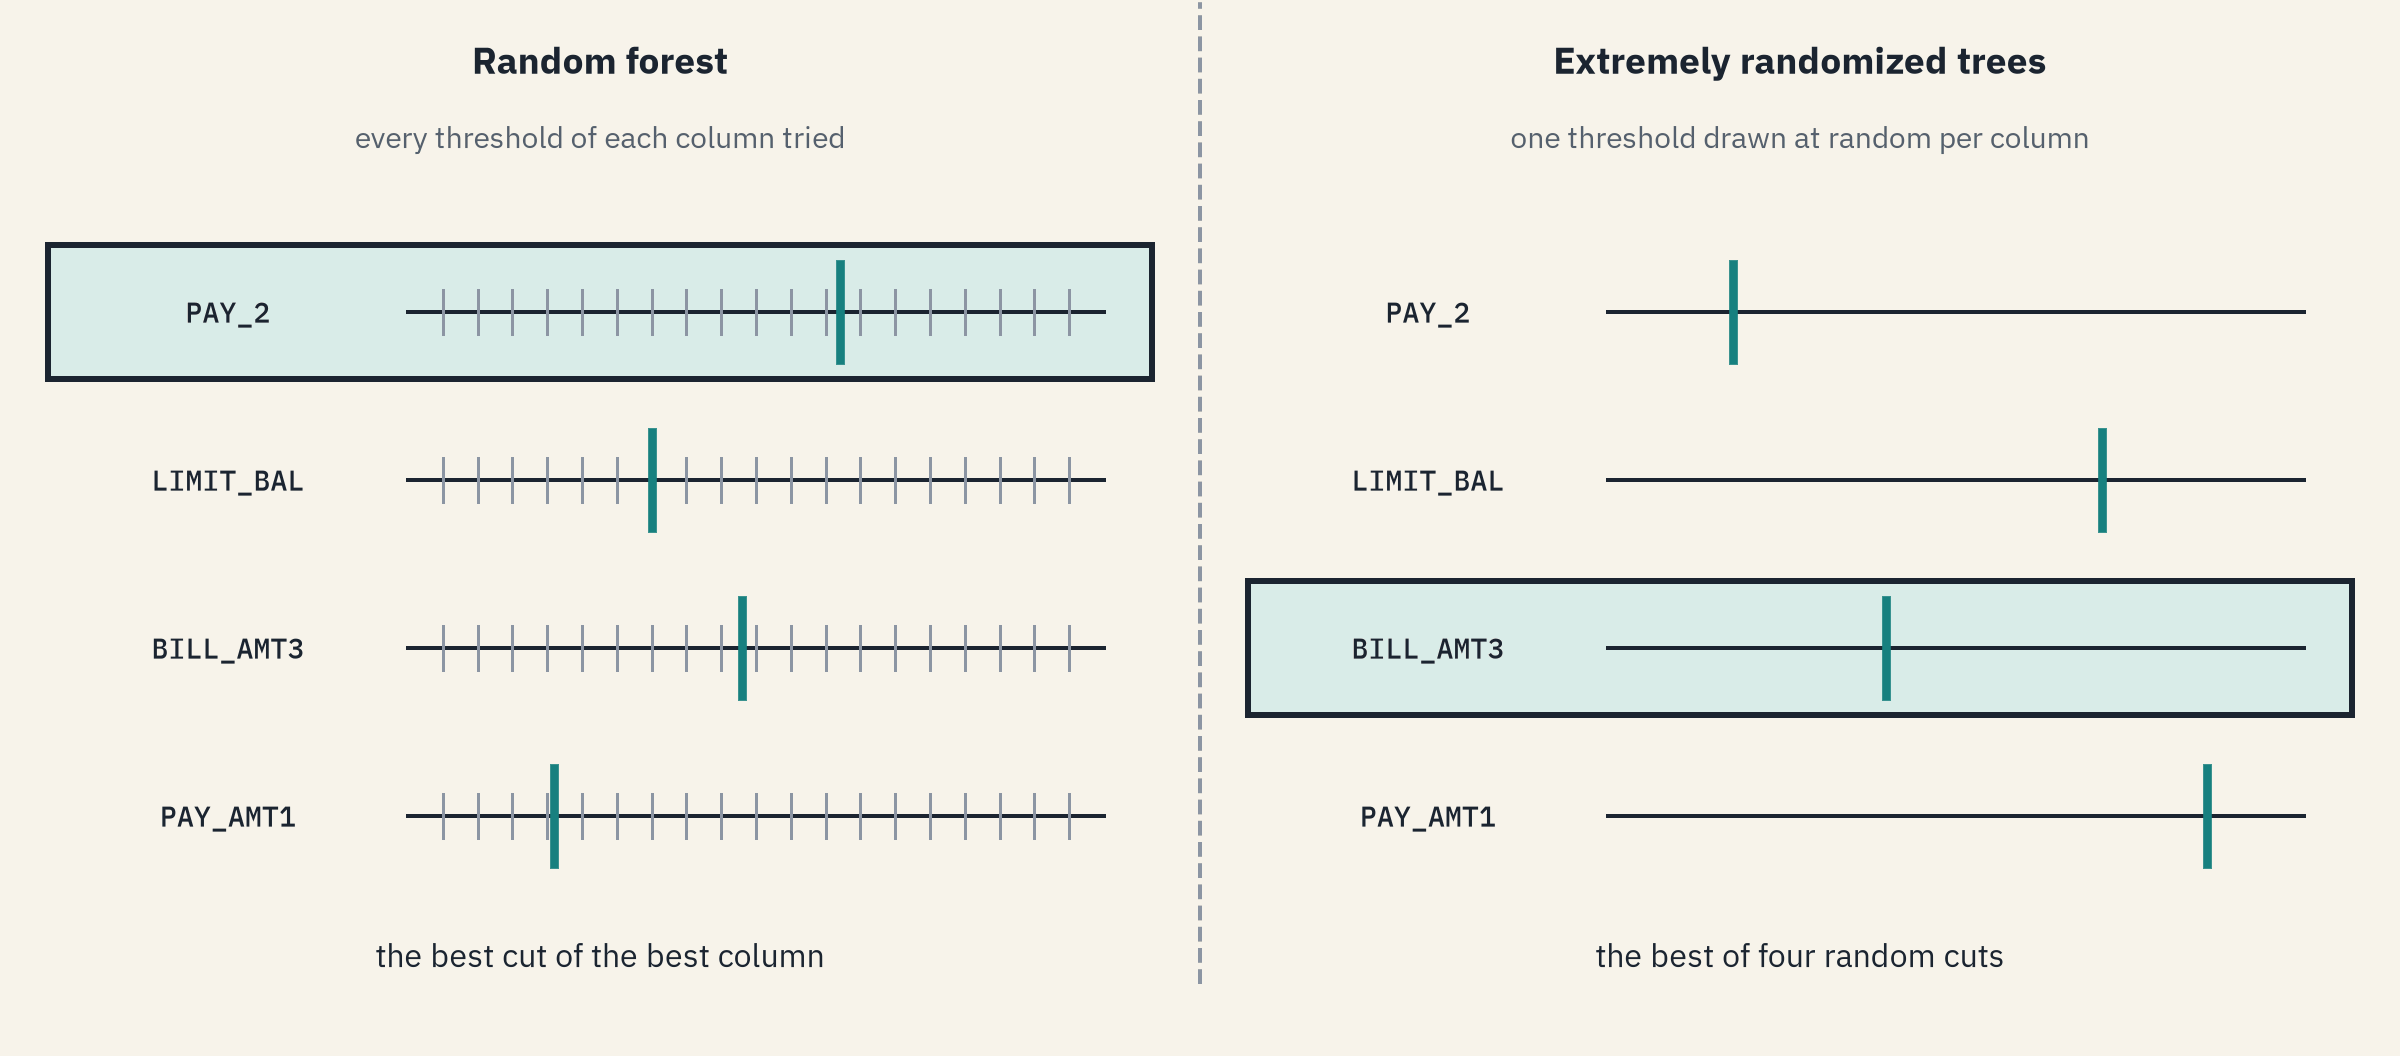

**Extremely randomized trees** go one step further: for each offered column they draw one threshold at random, and keep the best of those few cuts.
By default each tree is fitted on all 18,000 training rows, with no bootstrap sample (`bootstrap=False`), so there are no out-of-bag rows.
`ExtraTreesClassifier` takes the forest's settings.

**Predict 4**

Q. With the chosen forest's settings, 200 trees, 8 columns and 100-account leaves, what do extremely randomized trees score on the validation rows? Write down a number.

## Extra Trees With the Chosen Settings

In [34]:
# extremely randomized trees with the chosen forest's settings
extra = ExtraTreesClassifier(n_estimators=200, max_features=8, min_samples_leaf=100, random_state=SEED, n_jobs=1).fit(X_train, y_train)
extra_valid = extra.predict_proba(X_valid)[:, 1]
print("ROC AUC:", round(roc_auc_score(y_valid, extra_valid), 4), " Average precision:", round(average_precision_score(y_valid, extra_valid), 4))

ROC AUC: 0.7773  Average precision: 0.5427


In [35]:
# how alike and how strong the trees are, beside the chosen forest's
extra_correlations, extra_strength = describe_forest(extra)
chosen_correlations, chosen_strength = describe_forest(chosen)
print("Mean correlation:", round(extra_correlations.mean(), 4), " Chosen forest:", round(chosen_correlations.mean(), 4))
print("Strength:", round(extra_strength, 4), " Chosen forest:", round(chosen_strength, 4))

Mean correlation: 0.747  Chosen forest: 0.8434
Strength: 0.7334  Chosen forest: 0.7547


In [36]:
# the roots that ask PAY_0: the threshold each tree cut at
extra_cuts = pd.Series([round(t.tree_.threshold[0], 2) for t in extra.estimators_ if FEATURES[t.tree_.feature[0]] == "PAY_0"])
chosen_cuts = pd.Series([round(t.tree_.threshold[0], 2) for t in chosen.estimators_ if FEATURES[t.tree_.feature[0]] == "PAY_0"])
print("Chosen forest:", chosen_cuts.value_counts().to_dict())
print("Extra trees:", len(extra_cuts), "roots on PAY_0, cut at", extra_cuts.sort_values().tolist()[:8], "...")

Chosen forest: {1.5: 76}
Extra trees: 29 roots on PAY_0, cut at [-1.7, -1.47, -0.95, -0.71, -0.48, -0.32, -0.26, 0.1] ...


0.7773, below the chosen forest's 0.7844, with average precision 0.5427.

The trees agree less, 0.747 against 0.8434, and are weaker, 0.7334 against 0.7547.

All 76 of the chosen forest's roots on `PAY_0` cut at 1.5; the 29 extra trees that open on `PAY_0` cut wherever the draw fell.

**More randomness bought less agreement with weaker trees: the same trade, tipped the same way.**

# Model Performance Comparison

## Validation Rows, Every Model

In [37]:
# Course 4's pruned tree, refit with the settings Course 4's Day 9 chose
pruned_tree = DecisionTreeClassifier(class_weight="balanced", ccp_alpha=0.001, random_state=SEED).fit(X_train, y_train)

# every model on the validation rows, with its training ROC AUC and, where it has one, its out-of-bag ROC AUC
models = {"Course 4's pruned tree": pruned_tree, "Day 2's bag": bag, "default forest": forest, "chosen forest": chosen, "extra trees": extra}
comparison = pd.concat([model_performance_classification(m, X_valid, y_valid) for m in models.values()])
comparison.index = list(models)
comparison["Training ROC AUC"] = [auc(m, X_train, y_train) for m in models.values()]
comparison["Out-of-bag ROC AUC"] = [np.nan, roc_auc_score(y_train, bag.oob_decision_function_[:, 1]),
                                    roc_auc_score(y_train, forest.oob_decision_function_[:, 1]), chosen_oob, np.nan]
comparison

,ROC AUC,Accuracy,Recall,Precision,F1,Training ROC AUC,Out-of-bag ROC AUC
Course 4's pruned tree,0.7627,0.7683,0.5840,0.4805,0.5272,0.7691,NaN
Day 2's bag,0.7621,0.8165,0.3760,0.6464,0.4755,0.9996,0.7549
default forest,0.7604,0.8150,0.3745,0.6396,0.4724,0.9996,0.7554
chosen forest,0.7844,0.8192,0.3459,0.6790,0.4583,0.8204,0.7834
extra trees,0.7773,0.8170,0.3157,0.6880,0.4329,0.7916,NaN


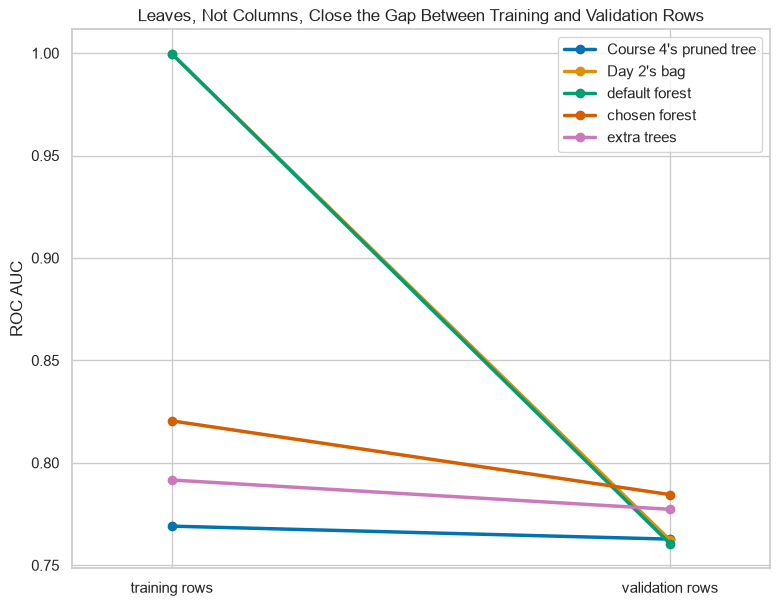

In [38]:
# a slope chart: each model's ROC AUC on its training rows and on the validation rows
fig, ax = plt.subplots(figsize=(9, 7))
for name in comparison.index:
    ax.plot([0, 1], [comparison.loc[name, "Training ROC AUC"], comparison.loc[name, "ROC AUC"]], marker="o", linewidth=2.5, label=name)
ax.set_xticks([0, 1], ["training rows", "validation rows"])
ax.set_xlim(-0.2, 1.2)
ax.set_ylabel("ROC AUC")
ax.set_title("Leaves, Not Columns, Close the Gap Between Training and Validation Rows")
ax.legend(loc="upper right")
plt.show()

The chosen forest leads on ROC AUC; Course 4's pruned tree, fitted with balanced weights, flags far more accounts at 0.5 and so leads on recall.

The bag and the default forest fall from 0.9996 on their training rows to about 0.76, their lines one on the other.

The chosen forest falls only from 0.8204 to 0.7844, and its out-of-bag 0.7834 sits 0.001 below its validation score.

**The chosen forest leads, and leaves, not columns, closed the training gap.**

# Insights and Conclusion

A random forest is bagging with a random handful of columns offered at each split.

Its full trees opened with 13 different questions, yet the score and the agreement barely moved: the status columns are cousins and full trees memorise.

Strength and agreement trade against each other, and on this file bigger leaves bought strength cheaply.

Out of bag, the leaf size moved the score by 0.042, the column count by 0.0075 and the trees by 0.0048.

The chosen forest scores 0.7844, 0.0007 above Day 2's chosen bag: here a well-leafed bag and a forest are nearly one model.

Extremely randomized trees went further and scored lower.

Every number describes this file, card accounts in Taiwan in 2005.

**Day 4 asks which columns the chosen forest leans on, and how far to trust the answer.**

# Wrapping Up

## You Can Now

By the end of this notebook, you can:

* Fit a random forest with `RandomForestClassifier` and read the first question of each of its trees.
* Measure a forest's strength and the agreement between its trees.
* Sweep `max_features` and `min_samples_leaf`, and draw every forest on one map.
* Choose a forest's settings out of bag and report it on validation rows.
* Watch a forest's score settle as `n_estimators` grows, and fit `ExtraTreesClassifier`.

## Exercises

Run this cell first: `check()` marks each answer as correct, not yet, or not attempted.

In [39]:
# check() compares your answer with the expected one
def check(label, answer, expected):
    if answer is ...:
        print(label + ": not attempted yet")
    elif isinstance(expected, float) and abs(answer - expected) < 1e-6:
        print(label + ": correct")
    elif answer == expected:
        print(label + ": correct")
    else:
        print(label + ": not yet. You have", answer)

### Exercise 1

**The Chosen Forest Without PAY_0**

Q. Fit the chosen forest, 200 trees, 8 columns per split and 100-account leaves, on every feature except `PAY_0`, and store its validation ROC AUC in `ex1_auc`.

In [40]:
# the chosen forest's settings on every feature but PAY_0
no_pay0 = RandomForestClassifier(n_estimators=200, max_features=8, min_samples_leaf=100, random_state=SEED, n_jobs=1)
no_pay0.fit(X_train.drop(columns="PAY_0"), y_train)
ex1_auc = auc(no_pay0, X_valid.drop(columns="PAY_0"), y_valid)
print(ex1_auc)

0.7582974779679188


In [41]:
check("Exercise 1 the forest without PAY_0", ex1_auc, 0.7582974779679188)

Exercise 1 the forest without PAY_0: correct


Without `PAY_0` the chosen forest scores 0.7583 against 0.7844, a fall of 0.0261.

How much the forest leans on each column is Day 4's question.

### Exercise 2

**Half the Columns at Every Split**

Q. Fit the chosen forest with `max_features=0.5` in place of 8. Store the number of columns it offers at each split in `ex2_columns` and its validation ROC AUC in `ex2_auc`.

In [42]:
# half the 19 columns at every split: max_features_ gives the whole part of 9.5
half = RandomForestClassifier(n_estimators=200, max_features=0.5, min_samples_leaf=100, oob_score=True,
                              random_state=SEED, n_jobs=1).fit(X_train, y_train)
ex2_columns = half.estimators_[0].max_features_
ex2_auc = auc(half, X_valid, y_valid)
print(ex2_columns, ex2_auc, roc_auc_score(y_train, half.oob_decision_function_[:, 1]))

9 0.784466263972788 0.7837413101430398


In [43]:
check("Exercise 2 the columns per split", ex2_columns, 9)
check("Exercise 2 the validation ROC AUC", ex2_auc, 0.784466263972788)

Exercise 2 the columns per split: correct
Exercise 2 the validation ROC AUC: correct


A share of 0.5 offers 9 of the 19 columns, and the forest scores 0.7845, level with 8 columns: the column count only fine-tunes.

### Exercise 3

**A Forest's Settings in One Dictionary**

Q. Write `forest_settings(model)` that returns a dictionary with the keys `"trees"`, `"leaf_size"` and `"columns_per_split"`, read from the fitted model (`len(model.estimators_)`, `model.min_samples_leaf`, and the first tree's `max_features_`), and store `forest_settings(chosen)` in `ex3_settings`.

In [44]:
# a forest's size, its leaf size, and the columns its first tree was offered at each split
def forest_settings(model):
    return {"trees": len(model.estimators_), "leaf_size": model.min_samples_leaf,
            "columns_per_split": model.estimators_[0].max_features_}

ex3_settings = forest_settings(chosen)
print(ex3_settings)

{'trees': 200, 'leaf_size': 100, 'columns_per_split': 8}


In [45]:
check("Exercise 3 the chosen forest's settings", ex3_settings, {"trees": 200, "leaf_size": 100, "columns_per_split": 8})

Exercise 3 the chosen forest's settings: correct


### Exercise 4: AI check

**The Forest That Offered Every Column**

You asked an AI assistant for a function that fits a random forest of 50 trees with 100-account leaves.
This came back.
It runs, and it scores well on the validation rows.
Test it, then find the one bug.

In [46]:
# written for this course in the style of an AI assistant's answer: it runs, and it has one bug
def make_forest():
    # a random forest: 50 trees, leaves of at least 100 accounts, a random choice of columns at every split
    return RandomForestClassifier(n_estimators=50, min_samples_leaf=100, max_features=None, random_state=SEED, n_jobs=1)

ai_forest = make_forest().fit(X_train, y_train)
print("Validation ROC AUC:", round(auc(ai_forest, X_valid, y_valid), 4))

Validation ROC AUC: 0.7837


In [47]:
# the test: a random forest offers each split fewer columns than the file has
assert ai_forest.estimators_[0].max_features_ < X_train.shape[1], "every column offered at every split: a bag, not a forest"

AssertionError: every column offered at every split: a bag, not a forest

Q. Fix the function, and store the mean correlation between the fixed forest's trees in `ex4_correlation`.

In [48]:
# the fix: "sqrt" offers 4 of the 19 columns at each split, where None offered every column
def make_forest():
    return RandomForestClassifier(n_estimators=50, min_samples_leaf=100, max_features="sqrt", random_state=SEED, n_jobs=1)

fixed_forest = make_forest().fit(X_train, y_train)
assert fixed_forest.estimators_[0].max_features_ < X_train.shape[1]
ex4_correlation = describe_forest(fixed_forest)[0].mean()
print(ex4_correlation, describe_forest(ai_forest)[0].mean())

0.7884805502649042 0.8549867678257549


In [49]:
check("Exercise 4 the fixed forest's correlation", ex4_correlation, 0.7884805502649042)

Exercise 4 the fixed forest's correlation: correct


With `max_features=None` the trees agree at 0.8550, the grid's bag; with `"sqrt"` they agree at 0.7885, the grid's 4-column forest.

## Congratulations!

You gave every split of every tree a random handful of columns and watched the trees open with thirteen different questions.
You found out why that alone changed little, measured strength and agreement, and drew thirty forests on one map.
You chose a forest out of bag, reported it on validation rows, and saw which setting moved the score most.
That is how a practitioner tunes a forest: by reading the trees, not by guessing.
In Day 4 you ask which columns your forest leans on, and how far to trust the answer.

[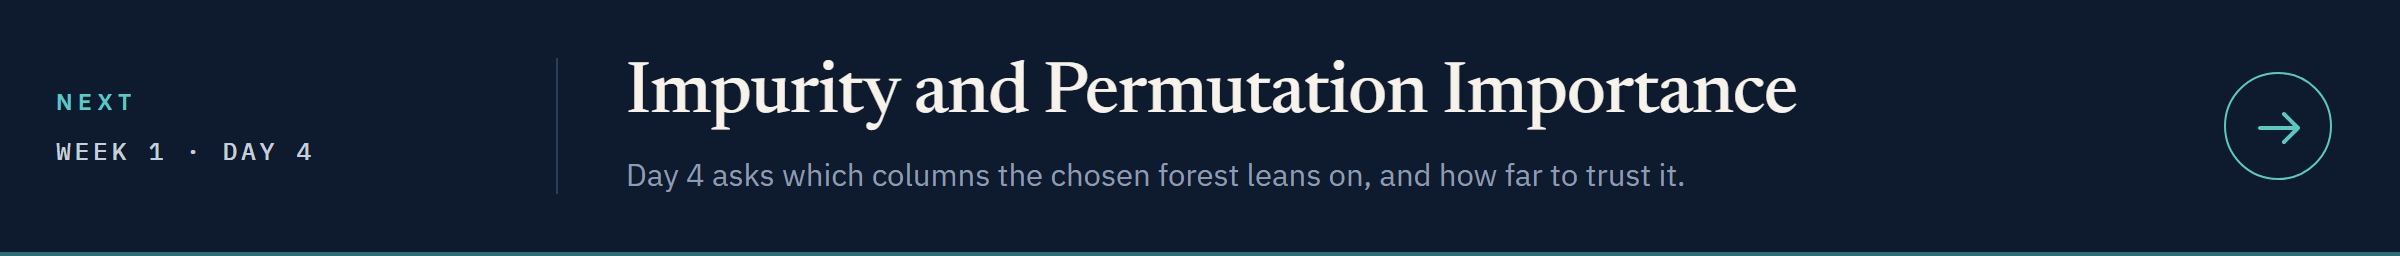](../day4/04_impurity_and_permutation_importance.ipynb)

[Open Day 4 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05_advanced_ml/week1/day4/04_impurity_and_permutation_importance.ipynb)